## Network Intrusion Detection System (IDS)

*   List item
*   List item




smote

In [ ]:
print("Network Intrusion Detection System (IDS)  ")

*###* data cleaing

> Add blockquote



In [ ]:
from google.colab import files
import io, pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import OrdinalEncoder, LabelEncoder, StandardScaler

print('Upload KDDTrain_.txt then KDDTest_.txt')
uploaded = files.upload()

# column names
col_names = [
    'duration','protocol_type','service','flag','src_bytes',
    'dst_bytes','land','wrong_fragment','urgent','hot',
    'num_failed_logins','logged_in','num_compromised','root_shell',
    'su_attempted','num_root','num_file_creations','num_shells',
    'num_access_files','num_outbound_cmds','is_host_login',
    'is_guest_login','count','srv_count','serror_rate',
    'srv_serror_rate','rerror_rate','srv_rerror_rate','same_srv_rate',
    'diff_srv_rate','srv_diff_host_rate','dst_host_count',
    'dst_host_srv_count','dst_host_same_srv_rate',
    'dst_host_diff_srv_rate','dst_host_same_src_port_rate',
    'dst_host_srv_diff_host_rate','dst_host_serror_rate',
    'dst_host_srv_serror_rate','dst_host_rerror_rate',
    'dst_host_srv_rerror_rate','label','difficulty'
]

# attack mapping
attack_map = {
    'normal': 'normal',

    'neptune': 'DoS','smurf': 'DoS','back': 'DoS','teardrop': 'DoS',
    'pod': 'DoS','land': 'DoS','apache2': 'DoS','udpstorm': 'DoS',
    'processtable': 'DoS','worm': 'DoS','mailbomb': 'DoS',

    'ipsweep': 'attack','nmap': 'attack','portsweep': 'attack','satan': 'attack',
    'mscan': 'attack','saint': 'attack',
    'guess_passwd': 'attack','ftp_write': 'attack','imap': 'attack',
    'phf': 'attack','multihop': 'attack','warezmaster': 'attack',
    'warezclient': 'attack','spy': 'attack',
    'buffer_overflow': 'attack','loadmodule': 'attack','rootkit': 'attack',
    'perl': 'attack','sqlattack': 'attack','xterm': 'attack','ps': 'attack'
}

#  parser
def parse_file(name):
    df = pd.read_csv(io.BytesIO(uploaded[name]), names=col_names)
    df.drop('difficulty', axis=1, inplace=True)
    df['label'] = df['label'].str.strip('.').map(attack_map).fillna('DoS')
    return df


keys = list(uploaded.keys())

train_key = next(k for k in keys if 'train' in k.lower())
test_key  = next(k for k in keys if 'test' in k.lower())

df_train = parse_file(train_key).drop_duplicates()
df_test  = parse_file(test_key).drop_duplicates()

print('\n✔ Loaded:')
print(len(df_train), len(df_test))


print('\nTrain distribution:')
print(df_train['label'].value_counts())

print('\nTest distribution:')
print(df_test['label'].value_counts())


# PREPROCESSING (CLEAN)

print('\n Preprocessing...')

cat_cols = ['protocol_type', 'service', 'flag']

cat_encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

cat_encoder.fit(df_train[cat_cols])

df_train[cat_cols] = cat_encoder.transform(df_train[cat_cols])
df_test[cat_cols]  = cat_encoder.transform(df_test[cat_cols])

# label encoding
le_label = LabelEncoder()
le_label.fit(df_train['label'])

df_train['label_enc'] = le_label.transform(df_train['label'])
df_test['label_enc']  = le_label.transform(df_test['label'])

# features
feature_cols = [c for c in df_train.columns if c not in ['label','label_enc']]

X_train = df_train[feature_cols].values.astype(np.float32)
y_train = df_train['label_enc'].values

X_test  = df_test[feature_cols].values.astype(np.float32)
y_test  = df_test['label_enc'].values

# scaling (for LR / NN)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print('\n✔ Classes:', list(le_label.classes_))
print('✔ Features:', X_train.shape[1])
print('✔ CLEAN PIPELINE READY')

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
le.fit(df_train['label'])

y_train = le.transform(df_train['label'])
y_test  = le.transform(df_test['label'])

print("Classes found:")
print(le.classes_)

print("\nNumber of classes:", len(le.classes_))

In [ ]:
feature_cols = [c for c in df_train.columns if c not in ['label', 'label_enc']]

X_train = df_train[feature_cols].values.astype(np.float32)
X_test  = df_test[feature_cols].values.astype(np.float32)

print(X_train.shape, X_test.shape)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

In [ ]:
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_sc,
    y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42
)

###Preprocessing

In [ ]:
from sklearn.preprocessing import OrdinalEncoder
# -----------------------------
# 1) Split raw data first
# -----------------------------
df_train_raw = df_train.copy()
df_test_raw = df_test.copy()

target_col = "label"
cat_cols = ["protocol_type", "service", "flag"]

# split X and y FIRST
X = df_train_raw.drop(columns=[target_col])
y = df_train_raw[target_col]

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [ ]:
# -----------------------------
# 2) Proper feature encoding (FIXED)
# -----------------------------

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# categorical + numerical split
cat_cols = ["protocol_type", "service", "flag"]
num_cols = [col for col in X_train.columns if col not in cat_cols]

# preprocessing pipeline
preprocess = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler(), num_cols)
    ]
)

# fit ONLY on training data
X_train_enc = preprocess.fit_transform(X_train)

# transform validation and test
X_val_enc = preprocess.transform(X_val)
X_test_enc = preprocess.transform(df_test_raw.drop(columns=[target_col], errors="ignore"))

In [ ]:
# -----------------------------
# 3) Fit label encoder on TRAIN only
# -----------------------------
label_encoder = LabelEncoder()
label_encoder.fit(df_train['label'])

y_train = label_encoder.transform(df_train['label'])
y_test  = label_encoder.transform(df_test['label'])

In [ ]:
# -----------------------------
# 4) Feature matrices (FIXED)
# -----------------------------

# use already encoded data from preprocessing step
X_train_final = X_train_enc
X_val_final   = X_val_enc
X_test_final  = X_test_enc

print("Train shape:", X_train_final.shape)
print("Val shape:", X_val_final.shape)
print("Test shape:", X_test_final.shape)

In [ ]:
# -----------------------------
# 5) SCALING (CORRECT VERSION)
# -----------------------------
from sklearn.preprocessing import StandardScaler


use_tree_models = True

if use_tree_models:
    X_train_final = X_train_enc
    X_val_final   = X_val_enc
    X_test_final  = X_test_enc
else:
    scaler = StandardScaler(with_mean=False)

    X_train_final = scaler.fit_transform(X_train_enc)
    X_val_final   = scaler.transform(X_val_enc)
    X_test_final  = scaler.transform(X_test_enc)

print("Final shapes:")
print("Train:", X_train_final.shape)
print("Val:", X_val_final.shape)
print("Test:", X_test_final.shape)

# Smote and Rescale

In [ ]:
# from imblearn.over_sampling import BorderlineSMOTE
# import numpy as np

# smote = BorderlineSMOTE(
#     random_state=42,
#     k_neighbors=3,
#     sampling_strategy="auto",
#     kind="borderline-1"
# )

# X_train_sm, y_train_sm = smote.fit_resample(X_train_enc, y_train)

# print("After BorderlineSMOTE:")
# unique, counts = np.unique(y_train_sm, return_counts=True)

# for cls, cnt in zip(unique, counts):
#     print(f"{label_encoder.classes_[cls]}: {cnt:,}")

In [ ]:
# The scaled SMOTE'd training data (X_train_sm_sc) is already created in cell RSB2hOdtRBIz.
# The scaled validation (X_val_sc) and test (X_test_sc) data are already created in cell 3ohF4acuQ_q-.
# This cell is redundant and can be cleared to avoid confusion.




```
`# This is formatted as code`
```

## logistic Regrssion (Baseline Model)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# LOGISTIC REGRESSION
# -----------------------------
lr = LogisticRegression(
    max_iter=2000,
    C=0.1,
    class_weight="balanced",
    solver="lbfgs",
    multi_class="auto"
)

# USE FINAL PIPELINE DATA
lr.fit(X_train_sc, y_train)

y_pred_lr = lr.predict(X_test_sc)

acc_lr = accuracy_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr, average="macro")

print("="*55)
print("LOGISTIC REGRESSION RESULTS")
print("="*55)
print(f"Accuracy : {acc_lr*100:.2f}%")
print(f"F1 Macro : {f1_lr:.4f}")
print("="*55)

print(classification_report(
    y_test,
    y_pred_lr,
    target_names=label_encoder.classes_,
    digits=3
))

cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

###XGBOOST

In [ ]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, classification_report

print("─" * 55)
print("Two-Stage XGBoost (FINAL FIXED VERSION)")
print("─" * 55)

# =====================================================
# CONSISTENT INPUTS
# =====================================================
X_train_final = X_train_sc
X_test_final  = X_test_sc

y_train_final = y_train
y_test_final  = y_test

normal_class = le_label.transform(["normal"])[0]

# =====================================================
# STAGE 1: Normal vs Attack
# =====================================================
y_train_bin = (y_train_final != normal_class).astype(int)

xgb1 = XGBClassifier(
    n_estimators=800,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb1.fit(X_train_final, y_train_bin, verbose=False)

stage1_pred = xgb1.predict(X_test_final)

# =====================================================
# STAGE 2: ONLY ATTACK TYPES (CRITICAL FIX)
# =====================================================

attack_mask_train = y_train_final != normal_class
attack_mask_test  = stage1_pred == 1

# split attack-only data
X_attack_train = X_train_final[attack_mask_train]
y_attack_train = y_train_final[attack_mask_train]

# IMPORTANT: re-encode ONLY attack labels
le_attack = LabelEncoder()
y_attack_train_enc = le_attack.fit_transform(y_attack_train)

xgb2 = XGBClassifier(
    n_estimators=800,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=len(le_attack.classes_),
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb2.fit(X_attack_train, y_attack_train_enc, verbose=False)

# =====================================================
# FINAL PREDICTION
# =====================================================
y_pred_final = np.full(len(y_test_final), normal_class, dtype=int)  # ✅ default = normal

if attack_mask_test.sum() > 0:
    attack_preds_enc = xgb2.predict(X_test_final[attack_mask_test])
    attack_preds = le_attack.inverse_transform(attack_preds_enc.astype(int))
    y_pred_final[attack_mask_test] = attack_preds
# =====================================================
# EVALUATION
# =====================================================
acc = accuracy_score(y_test_final, y_pred_final)
f1  = f1_score(y_test_final, y_pred_final, average="macro")

print("\nRESULTS")
print("=" * 40)
print(f"Accuracy : {acc*100:.2f}%")
print(f"F1 Macro : {f1:.4f}")
print("=" * 40)

print(
    classification_report(
        y_test_final,
        y_pred_final,
        target_names=le_label.classes_,
        digits=3
    )
)

───────────────────────────────────────────────────────
Two-Stage XGBoost (FINAL FIXED VERSION)
───────────────────────────────────────────────────────

RESULTS
Accuracy : 78.19%
F1 Macro : 0.7414
              precision    recall  f1-score   support

         DoS      0.962     0.757     0.847      8146
      attack      0.838     0.434     0.572      4684
      normal      0.688     0.971     0.805      9711

    accuracy                          0.782     22541
   macro avg      0.829     0.721     0.741     22541
weighted avg      0.818     0.782     0.772     22541



In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# =====================================================
# EVALUATION (USE EXISTING y_pred_final ONLY)
# =====================================================

acc_xgb = accuracy_score(y_test_final, y_pred_final)
f1_xgb  = f1_score(y_test_final, y_pred_final, average="macro")

print("=" * 55)
print("FINAL TWO-STAGE XGBOOST RESULTS")
print("=" * 55)
print(f"Accuracy : {acc_xgb * 100:.2f}%")
print(f"F1 Macro : {f1_xgb:.4f}")
print("=" * 55)

print(
    classification_report(
        y_test_final,
        y_pred_final,
        target_names=le_label.classes_,
        digits=3
    )
)

# =====================================================
# CONFUSION MATRIX
# =====================================================

cm = confusion_matrix(y_test_final, y_pred_final)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le_label.classes_,
    yticklabels=le_label.classes_
)

plt.title("Confusion Matrix - Two-Stage XGBoost")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# store final output
y_pred_xgb = y_pred_final

In [ ]:
#from sklearn.metrics import accuracy_score, f1_score, classification_report

#y_pred_xgb = xgb1.predict(X_test_sc)

#acc_xgb = accuracy_score(y_test, y_pred_xgb)
#f1_xgb = f1_score(y_test, y_pred_xgb, average="macro")

#print("="*55)
#print("XGBOOST RESULTS")
#print("="*55)
#print(f"Accuracy : {acc_xgb*100:.2f}%")
#print(f"F1 Macro : {f1_xgb:.4f}")

#print(classification_report(
 #   y_test,
  #  y_pred_xgb,
   # target_names=le_label.classes_,
    #digits=3
#))




## Random Forest Model


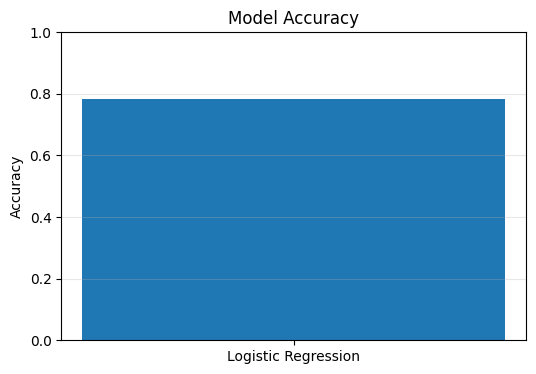

In [ ]:
models = ["Logistic Regression"]
accuracies = [acc_lr]

plt.figure(figsize=(6,4))
plt.bar(models, accuracies)
plt.ylim(0, 1)
plt.title("Model Accuracy")
plt.ylabel("Accuracy")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_sc, y_train)

y_pred_rf = rf.predict(X_test_sc)

## Deep learing Model (Neural Network )


In [ ]:
X_train_final = X_train_sc
y_train_final = y_train

X_test_final = X_test_sc
y_test_final = y_test

print(X_train_final.shape)
print(y_train_final.shape)

(125964, 41)
(125964,)


In [ ]:
feature_cols = [c for c in df_train.columns if c not in ['label', 'label_enc']]

X_train = df_train[feature_cols].values.astype(np.float32)
y_train = df_train['label_enc'].values

X_test = df_test[feature_cols].values.astype(np.float32)
y_test = df_test['label_enc'].values

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(125964, 41) (125964,)
(22541, 41) (22541,)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

In [ ]:
from tensorflow import keras
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import regularizers
import numpy as np

print('─' * 55)
print('Neural Network')
print('─' * 55)

weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

class_weights = dict(enumerate(weights))

model = keras.Sequential([
    keras.layers.Dense(
        256,
        activation='relu',
        kernel_regularizer=regularizers.l2(0.001),
        input_shape=(X_train_sc.shape[1],)
    ),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dropout(0.2),

    keras.layers.Dense(len(le_label.classes_), activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

lr_scheduler = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5
)

history = model.fit(
    X_train_sc,
    y_train,
    epochs=50,
    batch_size=512,
    validation_split=0.1,
    class_weight=class_weights,
    callbacks=[early_stop, lr_scheduler],
    verbose=1
)

y_pred_nn = np.argmax(model.predict(X_test_sc), axis=1)

acc_nn = accuracy_score(y_test, y_pred_nn)
f1_nn = f1_score(y_test, y_pred_nn, average="macro")

print("=" * 55)
print("NEURAL NETWORK RESULTS")
print("=" * 55)
print(f"Accuracy : {acc_nn*100:.2f}%")
print(f"F1 Macro : {f1_nn:.4f}")

print(classification_report(
    y_test,
    y_pred_nn,
    target_names=le_label.classes_,
    digits=3
))

───────────────────────────────────────────────────────
Neural Network
───────────────────────────────────────────────────────
Epoch 1/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.9418 - loss: 0.2314 - val_accuracy: 0.9809 - val_loss: 0.1468 - learning_rate: 5.0000e-04
Epoch 2/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.9778 - loss: 0.1215 - val_accuracy: 0.9848 - val_loss: 0.0956 - learning_rate: 5.0000e-04
Epoch 3/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9812 - loss: 0.1010 - val_accuracy: 0.9874 - val_loss: 0.0798 - learning_rate: 5.0000e-04
Epoch 4/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9838 - loss: 0.0877 - val_accuracy: 0.9868 - val_loss: 0.0717 - learning_rate: 5.0000e-04
Epoch 5/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9846 - loss: 0.0791 - val_accuracy: 0.9879 - val_loss: 0.0659 - learning_rate: 5.0000e-04
Epoch 6/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9859 - loss: 0.0727 

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf.fit(X_train_sc, y_train)

y_pred_rf = rf.predict(X_test_sc)

acc_rf = accuracy_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf, average="macro")

print("RF Accuracy:", acc_rf)
print("RF F1 Macro:", f1_rf)

RF Accuracy: 0.7407834612483918
RF F1 Macro: 0.6850042606372703


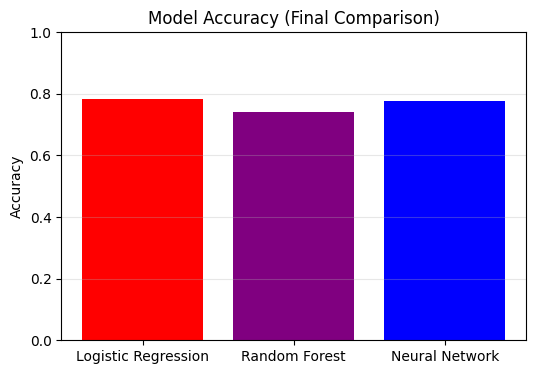

In [ ]:


models = ["Logistic Regression", "Random Forest", "Neural Network"]
accuracies = [acc_lr, acc_rf, acc_nn]

plt.figure(figsize=(6,4))
colors = ["red", "purple", "blue"]
plt.bar(models, accuracies , color = colors)
plt.ylim(0, 1)
plt.title("Model Accuracy (Final Comparison)")
plt.ylabel("Accuracy")
plt.grid(axis="y", alpha=0.3)
plt.show()

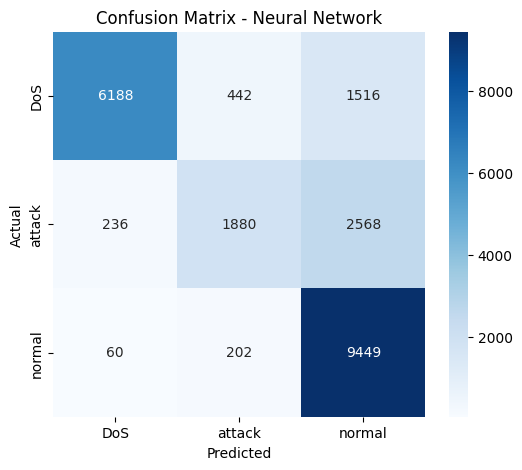

In [ ]:
cm_nn = confusion_matrix(y_test, y_pred_nn)

plt.figure(figsize=(6,5))
sns.heatmap(cm_nn, annot=True, fmt='d', cmap='Blues',
            xticklabels=le_label.classes_,
            yticklabels=le_label.classes_)

plt.title("Confusion Matrix - Neural Network")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    solver="lbfgs"
)

lr.fit(X_train_sc, y_train)

print("LR trained successfully")

LR trained successfully


## Results and comparison


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

# -------------------------------------------------
# Pick label encoder
# -------------------------------------------------
if 'le_label' in globals():
    class_names = le_label.classes_
elif 'label_encoder' in globals():
    class_names = label_encoder.classes_
else:
    class_names = None

# -------------------------------------------------
# Logistic Regression
# -------------------------------------------------
y_pred_lr = lr.predict(X_test_sc)
acc_lr = accuracy_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr, average='macro')

# -------------------------------------------------
# XGBoost
# -------------------------------------------------
y_pred_xgb = y_pred_final

acc_xgb = accuracy_score(y_test_final, y_pred_final)
f1_xgb = f1_score(y_test_final, y_pred_final, average='macro')

# -------------------------------------------------
# Neural Network
# -------------------------------------------------
y_pred_nn = np.argmax(model.predict(X_test_sc), axis=1)
acc_nn = accuracy_score(y_test, y_pred_nn)
f1_nn = f1_score(y_test, y_pred_nn, average='macro')

# -------------------------------------------------
# Results
# -------------------------------------------------
print('\n' + '=' * 55)
print('   FINAL RESULTS SUMMARY (CLEAN PIPELINE)')
print('=' * 55)
print(f"  {'Model':<25} {'Accuracy':>10} {'F1':>8}")
print('  ' + '-' * 43)
print(f"  {'Logistic Regression':<25} {acc_lr*100:>9.2f}% {f1_lr:>8.4f}")
print(f"  {'XGBoost':<25} {acc_xgb*100:>9.2f}% {f1_xgb:>8.4f}")
print(f"  {'Neural Network':<25} {acc_nn*100:>9.2f}% {f1_nn:>8.4f}")
print('=' * 55)

results = {
    'Logistic Regression': (acc_lr, f1_lr),
    'XGBoost': (acc_xgb, f1_xgb),
    'Neural Network': (acc_nn, f1_nn)
}

705/705 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step

   FINAL RESULTS SUMMARY (CLEAN PIPELINE)
  Model                       Accuracy       F1
  -------------------------------------------
  Logistic Regression           77.19%   0.7492
  XGBoost                       78.19%   0.7414
  Neural Network                77.21%   0.7188


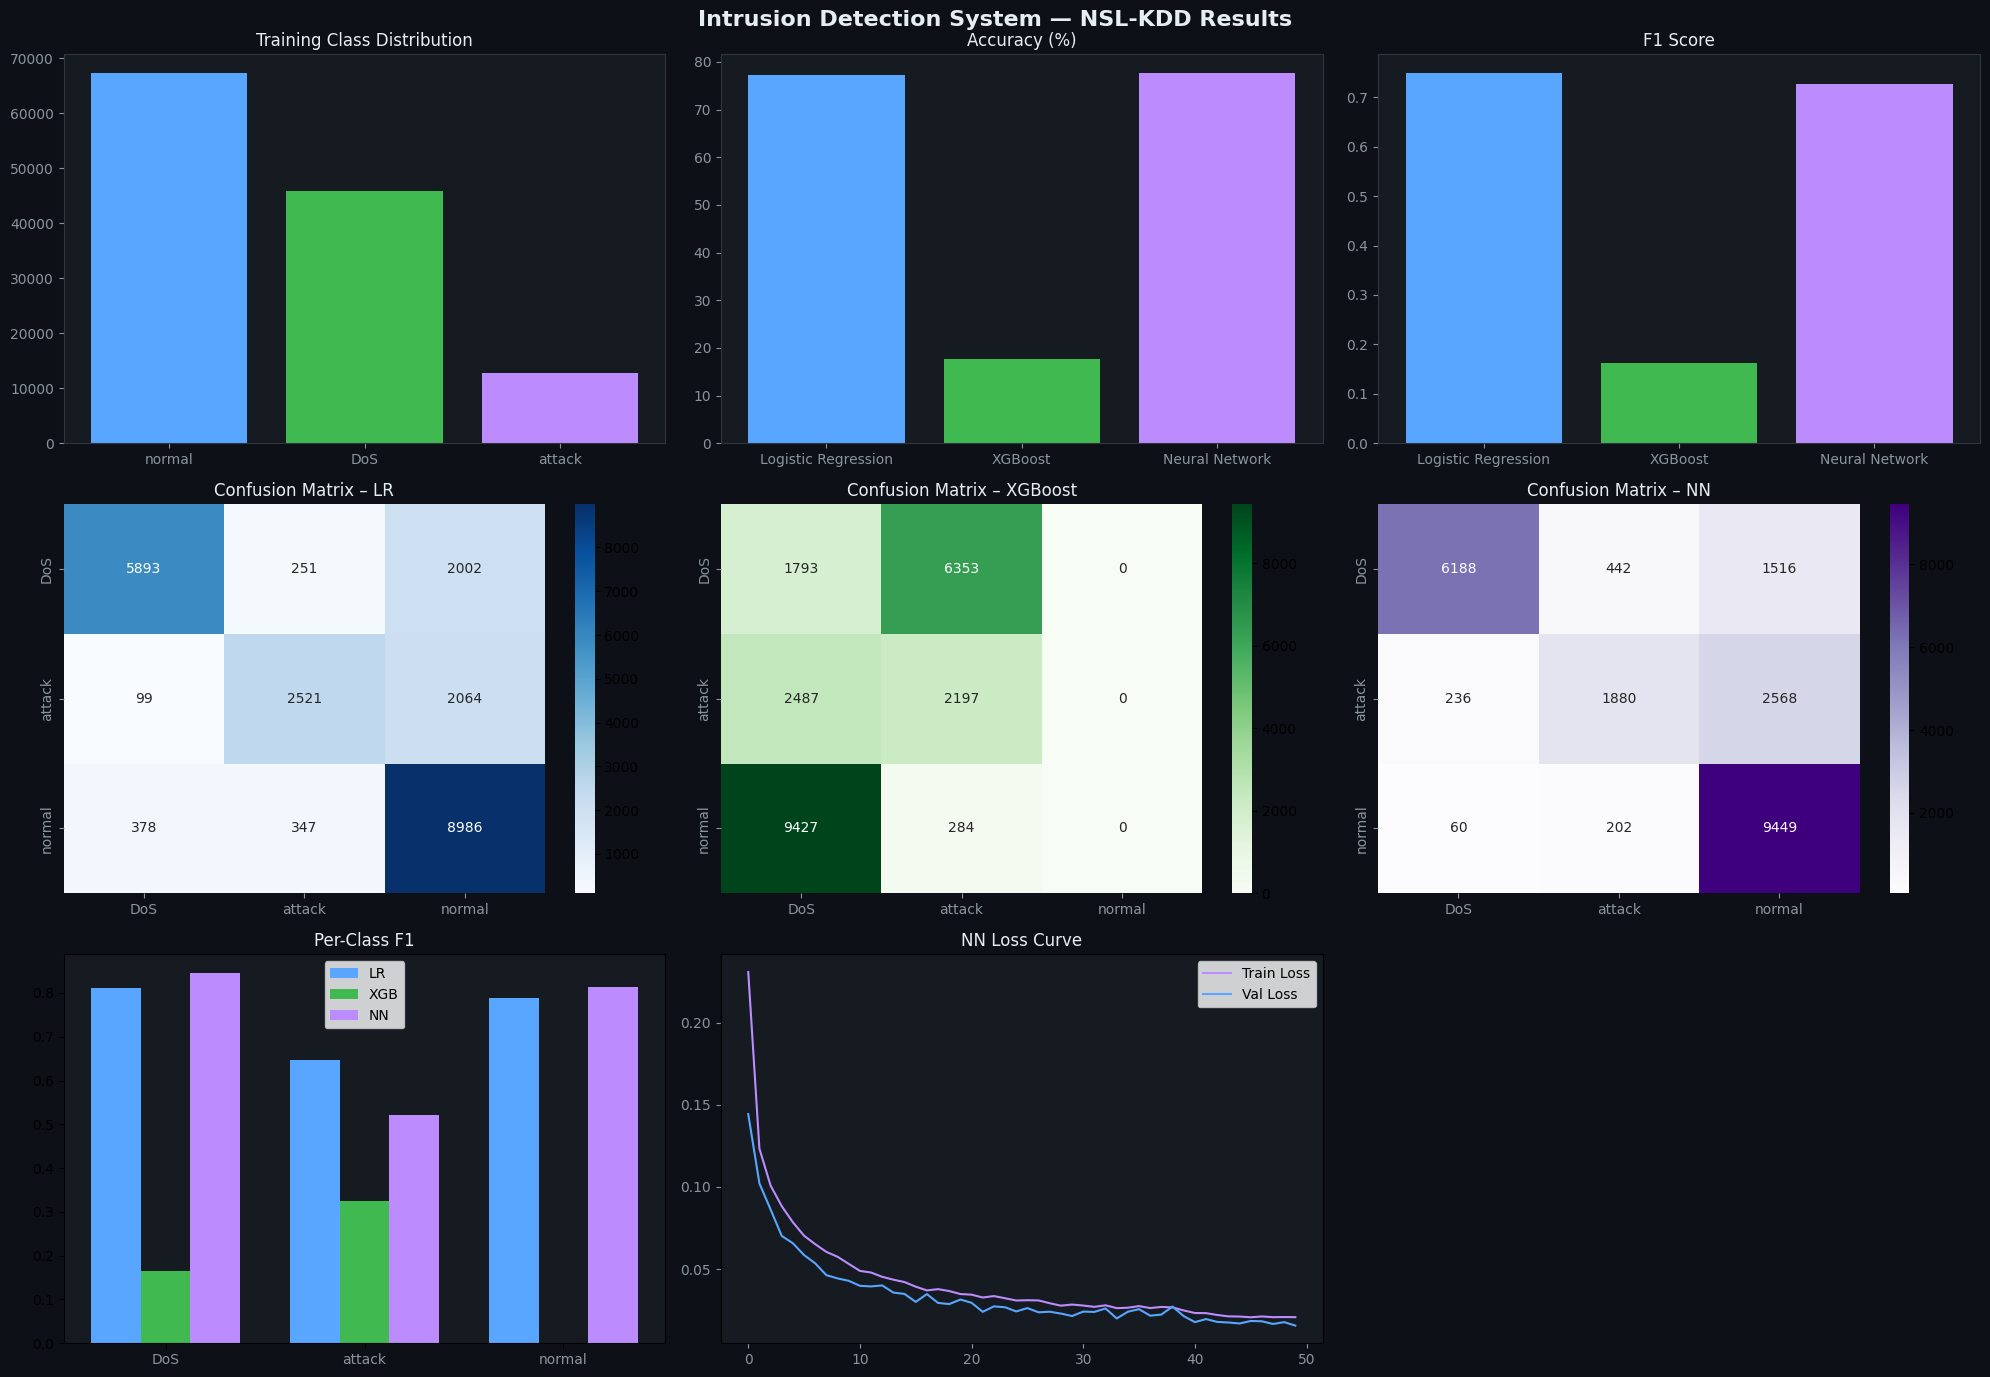

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix, f1_score

C = {
    'bg':'#0d1117','panel':'#161b22','border':'#30363d',
    'blue':'#58a6ff','green':'#3fb950','purple':'#bc8cff',
    'orange':'#d29922','red':'#f85149','text':'#e6edf3','muted':'#8b949e'
}

MC = [C['blue'], C['green'], C['purple']]
models_names = ['Logistic Regression', 'XGBoost', 'Neural Network']

fig, axes = plt.subplots(3, 3, figsize=(20, 14))
fig.patch.set_facecolor(C['bg'])

fig.suptitle(
    'Intrusion Detection System — NSL-KDD Results',
    fontsize=16, fontweight='bold', color=C['text']
)

ax1 = axes[0, 0]
ax1.set_facecolor(C['panel'])
tr_counts = df_train['label'].value_counts()
ax1.bar(tr_counts.index, tr_counts.values, color=MC[:len(tr_counts)])
ax1.set_title('Training Class Distribution', color=C['text'])
ax1.tick_params(colors=C['muted'])
for sp in ax1.spines.values():
    sp.set_color(C['border'])

ax2 = axes[0, 1]
ax2.set_facecolor(C['panel'])
accs = [acc_lr*100, acc_xgb*100, acc_nn*100]
ax2.bar(models_names, accs, color=MC)
ax2.set_title('Accuracy (%)', color=C['text'])
ax2.tick_params(colors=C['muted'])
for sp in ax2.spines.values():
    sp.set_color(C['border'])

ax3 = axes[0, 2]
ax3.set_facecolor(C['panel'])
f1s = [f1_lr, f1_xgb, f1_nn]
ax3.bar(models_names, f1s, color=MC)
ax3.set_title('F1 Score', color=C['text'])
ax3.tick_params(colors=C['muted'])
for sp in ax3.spines.values():
    sp.set_color(C['border'])

cms = [
    confusion_matrix(y_test, y_pred_lr),
    confusion_matrix(y_test, y_pred_xgb),
    confusion_matrix(y_test, y_pred_nn)
]

cmaps = ['Blues', 'Greens', 'Purples']
titles = ['LR', 'XGBoost', 'NN']

for i in range(3):
    ax = axes[1, i]
    ax.set_facecolor(C['panel'])
    sns.heatmap(
        cms[i], annot=True, fmt='d', cmap=cmaps[i],
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        ax=ax
    )
    ax.set_title(f'Confusion Matrix – {titles[i]}', color=C['text'])
    ax.tick_params(colors=C['muted'])

ax7 = axes[2, 0]
ax7.set_facecolor(C['panel'])

cl = list(label_encoder.classes_)
f1_per = [
    f1_score(y_test, y_pred_lr, average=None),
    f1_score(y_test, y_pred_xgb, average=None),
    f1_score(y_test, y_pred_nn, average=None)
]

x = np.arange(len(cl))
w = 0.25

for j, (vals, color, lbl) in enumerate(zip(f1_per, MC, ['LR', 'XGB', 'NN'])):
    ax7.bar(x + (j-1)*w, vals, w, label=lbl, color=color)

ax7.set_xticks(x)
ax7.set_xticklabels(cl, color=C['muted'])
ax7.set_title('Per-Class F1', color=C['text'])
ax7.legend()

ax8 = axes[2, 1]
ax8.set_facecolor(C['panel'])

if hasattr(model, "history") and model.history is not None:
    ax8.plot(model.history.history['loss'], label='Train Loss', color=C['purple'])
    ax8.plot(model.history.history['val_loss'], label='Val Loss', color=C['blue'])
    ax8.legend()

ax8.set_title('NN Loss Curve', color=C['text'])
ax8.tick_params(colors=C['muted'])

axes[2, 2].axis('off')

plt.tight_layout()
plt.show()

### PLOT

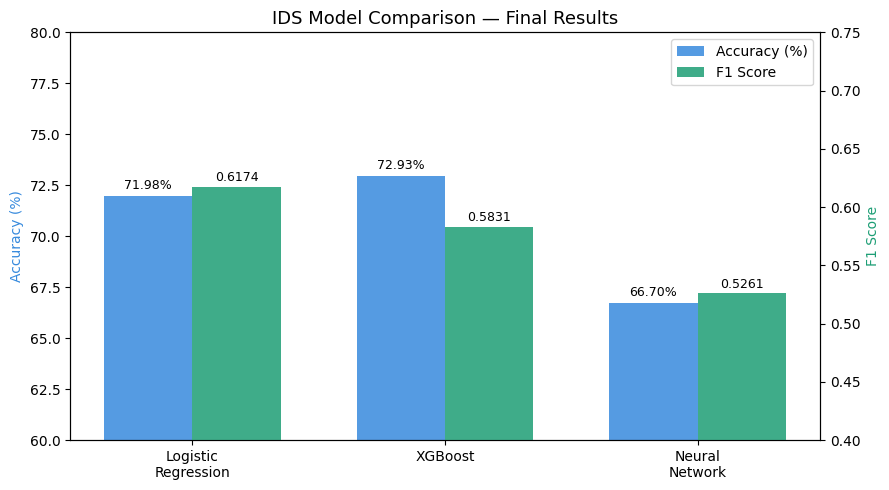

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = ['Logistic\nRegression', 'XGBoost', 'Neural\nNetwork']
accuracy = [71.98, 72.93, 66.70]
f1_scores = [0.6174, 0.5831, 0.5261]

x = np.arange(len(models))
width = 0.35

fig, ax1 = plt.subplots(figsize=(9, 5))
ax2 = ax1.twinx()

bars1 = ax1.bar(x - width/2, accuracy, width, label='Accuracy (%)', color='#378ADD', alpha=0.85)
bars2 = ax2.bar(x + width/2, f1_scores, width, label='F1 Score', color='#1D9E75', alpha=0.85)

ax1.set_ylabel('Accuracy (%)', color='#378ADD')
ax2.set_ylabel('F1 Score', color='#1D9E75')
ax1.set_xticks(x); ax1.set_xticklabels(models)
ax1.set_ylim(60, 80); ax2.set_ylim(0.4, 0.75)

for bar in bars1: ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.2, f'{bar.get_height():.2f}%', ha='center', va='bottom', fontsize=9)
for bar in bars2: ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.002, f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=9)

lines = [plt.Rectangle((0,0),1,1,fc='#378ADD',alpha=0.85), plt.Rectangle((0,0),1,1,fc='#1D9E75',alpha=0.85)]
ax1.legend(lines, ['Accuracy (%)', 'F1 Score'], loc='upper right')
plt.title('IDS Model Comparison — Final Results', fontsize=13)
plt.tight_layout(); plt.show()